# Persian Search Engine on the Hamshahri Corpus

This notebook implements preprocessing, an inverted index, BM25, a smoothed query language model, TF–IDF cosine similarity, a weighted hybrid ranker, and relevance-based evaluation.

**Dataset required locally:** see `README.md`. The corpus and relevance files are not bundled in this repository.


Preprocess the Documents

In [14]:
from pathlib import Path
import os
import re

# Set this to the directory containing HamshahriCorpus/, Queries/,
# RelevanceAssessment/, and persian_stopwords.txt.
DATA_DIR = os.environ.get("HAMSHAHRI_DATA_DIR", "./HamshahriData")

def load_stopwords(path='HamshahriData/persian_stopwords.txt'):
    stopwords = set()
    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            w = line.strip()
            if w:
                stopwords.add(w)
    return stopwords


def normalize_persian(text):
    # Arabic → Persian normalizations
    text = text.replace("ي", "ی").replace("ك", "ک")

    # Remove English letters
    text = re.sub(r"[A-Za-z]", " ", text)

    # Keep ONLY Persian letters + Persian digits + spaces
    text = re.sub(r"[^۰-۹ء-ی\s]", " ", text)

    # Normalize spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()




def tokenize(text, stopwords=None):
    tokens = text.split()               
    if stopwords:
        tokens = [t for t in tokens if t not in stopwords]
    return tokens


def preprocess_document(text, stopwords):
    text = normalize_persian(text)
    tokens = tokenize(text, stopwords)
    tokens.sort()                       # alphabetical order
    unique_terms = sorted(set(tokens))  # unique sorted list
    return tokens, unique_terms



def load_hamshahri_corpus(base_path):
    all_docs = {}

    # Loop through year folders
    for year in ["2003", "2004", "2005", "2006", "2007"]:
        year_path = os.path.join(base_path, year)

        # Loop through all files in that year
        for filename in os.listdir(year_path):
            file_path = os.path.join(year_path, filename)

            # Read file content
            with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
                text = f.read()

            # Use filename as document ID
            doc_id = filename.replace(".ham", "")
            all_docs[doc_id] = text

    return all_docs


def preprocess_hamshahri(base_path):
    raw_docs = load_hamshahri_corpus(base_path)
    stopwords = load_stopwords()

    all_terms = {}
    all_unique = {}

    for doc_id, text in raw_docs.items():
        tokens, unique_terms = preprocess_document(text, stopwords)
        all_terms[doc_id] = tokens
        all_unique[doc_id] = unique_terms

    return all_terms, all_unique


base_path = os.path.join(DATA_DIR, "HamshahriCorpus")
all_terms, all_unique_terms = preprocess_hamshahri(base_path)

print("Example doc ID:", list(all_terms.keys())[0])
print("Tokens:", all_terms[list(all_terms.keys())[0]][:50])
print("Unique terms:", all_unique_terms[list(all_unique_terms.keys())[0]][:50])




Example doc ID: HAM2-820806-003
Tokens: ['آزاد', 'آموزش', 'آموزش', 'اتحادیه', 'اتحادیه', 'اتحادیه', 'احساس', 'ارائه', 'استاندارد', 'استاندارد', 'استانداردهای', 'استفاده', 'استفاده', 'استفاده', 'اطلا', 'اطمینان', 'افراد', 'افرادی', 'افزایش', 'افزود', 'افزود', 'افزود', 'اقشار', 'التحصیلا', 'انتقاد', 'اندازی', 'اندازی', 'انواع', 'انواع', 'اهمیت', 'اپتیک', 'ایجاد', 'ایرنا', 'این', 'این', 'این', 'این', 'این', 'این', 'این', 'این', 'این', 'بازارچه', 'باشند', 'باید', 'برای', 'برای', 'برای', 'برای', 'برای']
Unique terms: ['آزاد', 'آموزش', 'اتحادیه', 'احساس', 'ارائه', 'استاندارد', 'استانداردهای', 'استفاده', 'اطلا', 'اطمینان', 'افراد', 'افرادی', 'افزایش', 'افزود', 'اقشار', 'التحصیلا', 'انتقاد', 'اندازی', 'انواع', 'اهمیت', 'اپتیک', 'ایجاد', 'ایرنا', 'این', 'بازارچه', 'باشند', 'باید', 'برای', 'برخورد', 'برخی', 'بلا', 'بودن', 'بینایی', 'تأثیر', 'تجهیزات', 'تخصص', 'تراشی', 'تسهیلا', 'تقلبی', 'تمایل', 'تهران', 'تهیه', 'توصیه', 'جبران', 'حالی', 'حساسیت', 'حضور', 'حیت', 'خبرنگار', 'خرید']


Build Dictionary and Postings List

In [15]:
import math


def build_vocabulary(all_unique_terms):
    vocab = set()
    for terms in all_unique_terms.values():
        vocab.update(terms)
    return sorted(vocab)



# Postings List
def build_inverted_index(all_unique_terms):
    inverted = {}
    for doc_id, terms in all_unique_terms.items():
        for term in terms:
            if term not in inverted:
                inverted[term] = []
            inverted[term].append(doc_id)
    return inverted


def compute_tf(all_terms):
    tf = {}   # {doc_id: {term: count}}
    for doc_id, tokens in all_terms.items():
        tf[doc_id] = {}
        for t in tokens:
            tf[doc_id][t] = tf[doc_id].get(t, 0) + 1
    return tf


def compute_df(inverted_index):
    df = {term: len(postings) for term, postings in inverted_index.items()}
    return df


def compute_idf(df, total_docs):
    idf = {term: math.log(total_docs / df_val) for term, df_val in df.items()}
    return idf



def build_index_structures(all_terms, all_unique_terms):
    vocab = build_vocabulary(all_unique_terms)
    inverted_index = build_inverted_index(all_unique_terms)
    tf = compute_tf(all_terms)
    df = compute_df(inverted_index)
    total_docs = len(all_terms)
    idf = compute_idf(df, total_docs)

    return vocab, inverted_index, tf, df, idf

vocab, inverted, tf, df, idf = build_index_structures(all_terms, all_unique_terms)
print("Vocabulary size:", len(vocab))
print("First 50 terms:", vocab[:50])
sample_term = vocab[500]
print("Term:", sample_term)
print("Postings list:", inverted[sample_term][:10])
sample_doc = list(tf.keys())[0]
print("Term frequencies in:", sample_doc)
print(tf[sample_doc])
print("DF of sample term:", df[sample_term])
print("IDF of sample term:", idf[sample_term])


Vocabulary size: 49853
First 50 terms: ['ء', 'ءالدین', 'ءالله', 'ءامنوا', 'ءتفاهماتی', 'آ', 'آئروبیک', 'آئورت', 'آئورو', 'آئورولوئیجی', 'آئویی', 'آئیم', 'آئین', 'آئینه', 'آئینی', 'آئیک', 'آاس', 'آب', 'آباء', 'آباابان', 'آبابا', 'آباد', 'آبادان', 'آبادانی', 'آبادسازی', 'آبادشدن', 'آبادنو', 'آباده', 'آبادها', 'آبادهای', 'آبادهفته', 'آبادگران', 'آبادی', 'آبادیان', 'آبادیهای', 'آبار', 'آبارعلی', 'آبان', 'آبانبارهایی', 'آبانماه', 'آباچا', 'آباژور', 'آبتینی', 'آبخوان', 'آبخوانداری', 'آبخور', 'آبخورهای', 'آبخیز', 'آبخیزدار', 'آبخیزداری']
Term: آزادراهی
Postings list: ['HAM2-850301-110']
Term frequencies in: HAM2-820806-003
{'آزاد': 1, 'آموزش': 2, 'اتحادیه': 3, 'احساس': 1, 'ارائه': 1, 'استاندارد': 2, 'استانداردهای': 1, 'استفاده': 3, 'اطلا': 1, 'اطمینان': 1, 'افراد': 1, 'افرادی': 1, 'افزایش': 1, 'افزود': 3, 'اقشار': 1, 'التحصیلا': 1, 'انتقاد': 1, 'اندازی': 2, 'انواع': 2, 'اهمیت': 1, 'اپتیک': 1, 'ایجاد': 1, 'ایرنا': 1, 'این': 9, 'بازارچه': 1, 'باشند': 1, 'باید': 1, 'برای': 5, 'برخورد': 1, 'برخی'

Probabilistic Model – Okapi BM25

In [16]:
import math

class BM25_LongQuery:
    def __init__(self, tf, df, idf, all_terms, k1=1.2, b=0.75, k3=1.5):
        self.tf = tf
        self.df = df
        self.idf = idf
        self.all_terms = all_terms
        self.k1 = k1
        self.b = b
        self.k3 = k3
        
        # Document lengths
        self.doc_len = {doc: len(tokens) for doc, tokens in all_terms.items()}
        self.avgdl = sum(self.doc_len.values()) / len(self.doc_len)

    def preprocess_query(self, query, stopwords=None):
        query = normalize_persian(query)
        tokens = tokenize(query, stopwords)
        
        # Compute tf for terms in the query
        q_tf = {}
        for t in tokens:
            q_tf[t] = q_tf.get(t, 0) + 1
            
        return tokens, q_tf

    def score(self, query_terms, query_tf, doc_id):
        score = 0.0
        doc_length = self.doc_len[doc_id]

        for term in query_terms:
            if term not in self.tf[doc_id]:
                continue

            f_td = self.tf[doc_id][term]          # doc term freq
            f_tq = query_tf[term]                # query term freq
            
            idf = self.idf.get(term, 0)

            # Document term frequency component
            doc_factor = ((self.k1 + 1) * f_td) / (
                self.k1 * ((1 - self.b) + self.b * (doc_length / self.avgdl)) + f_td
            )

            # Query term frequency component
            query_factor = ((self.k3 + 1) * f_tq) / (self.k3 + f_tq)

            score += idf * doc_factor * query_factor

        return score

    def rank(self, query, stopwords=None, top_k=10):
        query_terms, q_tf = self.preprocess_query(query, stopwords)

        scores = {}
        for doc_id in self.all_terms:
            scores[doc_id] = self.score(query_terms, q_tf, doc_id)

        ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)
        return ranked[:top_k]


bm25 = BM25_LongQuery(tf, df, idf, all_terms, k1=1.2, b=0.75, k3=1.5)

query = "اقتصاد ایران"
results = bm25.rank(query, stopwords=load_stopwords(), top_k=10)

for doc_id, score in results:
    print(doc_id, score)


HAM2-830708-081 6.884526462966054
HAM2-830216-126 6.837822108475288
HAM2-811203-019 6.797860392916531
HAM2-840412-145 6.755321888641653
HAM2-851223-081 6.593782941092229
HAM2-840217-124 6.538670104957649
HAM2-851126-087 6.52013327140455
HAM2-830624-086 6.506708305869356
HAM2-851012-091 6.506669256987059
HAM2-811214-032 6.400779404112515


In [17]:
import math

class LanguageModel:
    def __init__(self, tf, all_terms, smoothing="dirichlet", lam=0.2, mu=2000):
        self.tf = tf
        self.all_terms = all_terms
        self.smoothing = smoothing
        self.lam = lam
        self.mu = mu
        
        # Document lengths
        self.doc_len = {doc: len(tokens) for doc, tokens in all_terms.items()}
        self.avgdl = sum(self.doc_len.values()) / len(self.doc_len)
        
        # Collection length
        self.collection_len = sum(self.doc_len.values())
        
        # Collection frequency
        self.cf = {}
        for tokens in all_terms.values():
            for t in tokens:
                self.cf[t] = self.cf.get(t, 0) + 1

    def preprocess_query(self, query, stopwords=None):
        query = normalize_persian(query)
        tokens = tokenize(query, stopwords)
        q_tf = {}
        for t in tokens:
            q_tf[t] = q_tf.get(t, 0) + 1
        return tokens, q_tf

    # Probability P(t|d)
    def probability(self, term, doc_id):
        f_td = self.tf[doc_id].get(term, 0)
        len_d = self.doc_len[doc_id]
        cf_t = self.cf.get(term, 0)
        
        if self.smoothing == "jelinek":
            # JM smoothing
            p_doc = f_td / len_d if len_d > 0 else 0
            p_col = cf_t / self.collection_len
            return (1 - self.lam) * p_doc + self.lam * p_col
        
        else:  # Dirichlet smoothing
            p_col = cf_t / self.collection_len
            return (f_td + self.mu * p_col) / (len_d + self.mu)


    def score(self, query_terms, q_tf, doc_id):
        score = 0.0
        for term in query_terms:
            p = self.probability(term, doc_id)
            if p > 0:
                score += q_tf[term] * math.log(p)
        return score


    def rank(self, query, stopwords=None, top_k=10):
        query_terms, q_tf = self.preprocess_query(query, stopwords)
        scores = {}
        for doc_id in self.all_terms:
            scores[doc_id] = self.score(query_terms, q_tf, doc_id)
        ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)
        return ranked[:top_k]


lm = LanguageModel(tf, all_terms, smoothing="dirichlet", mu=2000)
results = lm.rank("اقتصاد ایران", stopwords=load_stopwords(), top_k=10)
for doc, score in lm.rank("نفت ایران", top_k=5):
    print(doc, score)


HAM2-820814-028 -9.111446685133206
HAM2-850218-039 -9.493726703913833
HAM2-840330-069 -9.78784630898365
HAM2-831227-066 -9.836461697167156
HAM2-820329-103 -9.8568141334205


In [18]:
import math

class VectorSpaceModel:
    def __init__(self, tf, idf, all_terms):
        self.tf = tf
        self.idf = idf
        self.all_terms = all_terms

        # Build TF-IDF vectors for all documents
        self.doc_vectors = {}      # {doc_id: {term: weight}}
        self.doc_norms = {}        # vector length for cosine
        
        self.build_doc_vectors()


    # Build document TF-IDF vectors
    def build_doc_vectors(self):
        for doc_id, term_freqs in self.tf.items():
            vector = {}
            norm_sq = 0

            for term, f_td in term_freqs.items():
                weight = f_td * self.idf.get(term, 0)   # tf * idf
                vector[term] = weight
                norm_sq += weight * weight

            self.doc_vectors[doc_id] = vector
            self.doc_norms[doc_id] = math.sqrt(norm_sq) if norm_sq > 0 else 0


    def make_query_vector(self, query, stopwords=None):
        query = normalize_persian(query)
        tokens = tokenize(query, stopwords)

        # term frequency in query
        q_tf = {}
        for t in tokens:
            q_tf[t] = q_tf.get(t, 0) + 1

        vector = {}
        norm_sq = 0

        for t, f_tq in q_tf.items():
            idf = self.idf.get(t, 0)
            weight = f_tq * idf
            vector[t] = weight
            norm_sq += weight * weight

        return vector, math.sqrt(norm_sq) if norm_sq > 0 else 0

    # Cosine Similarity between query and document
    def cosine(self, q_vec, q_norm, doc_id):
        doc_vec = self.doc_vectors[doc_id]
        doc_norm = self.doc_norms[doc_id]

        if q_norm == 0 or doc_norm == 0:
            return 0

        # dot product
        dot = 0
        for t, wq in q_vec.items():
            dot += wq * doc_vec.get(t, 0)

        return dot / (q_norm * doc_norm)

    # Rank documents
    def rank(self, query, stopwords=None, top_k=10):
        q_vec, q_norm = self.make_query_vector(query, stopwords)

        scores = {}
        for doc_id in self.all_terms:
            scores[doc_id] = self.cosine(q_vec, q_norm, doc_id)

        ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)
        return ranked[:top_k]

vsm = VectorSpaceModel(tf, idf, all_terms)

query = "اقتصاد ایران"
results = vsm.rank(query, stopwords=load_stopwords(), top_k=10)

for doc_id, score in results:
    print(doc_id, score)


HAM2-811203-019 0.330545658980548
HAM2-830216-126 0.32472619992078017
HAM2-840412-145 0.31233636992656266
HAM2-830708-081 0.31149817842598565
HAM2-851216-032 0.27773300180104205
HAM2-841206-149 0.2572190473611854
HAM2-840217-124 0.25012047851805763
HAM2-840614-063 0.25005478214241394
HAM2-811214-032 0.24682237906758095
HAM2-851012-091 0.22517907193931885


In [19]:
class HybridModel:
    """Weighted rank fusion after per-query min-max score normalization.

    Raw BM25, log language-model, and cosine scores have different scales;
    normalizing each model's scores makes their weighted combination meaningful.
    """
    def __init__(self, bm25_model, lm_model, vsm_model,
                 w_bm25=0.5, w_lm=0.3, w_vsm=0.2):
        self.bm25 = bm25_model
        self.lm = lm_model
        self.vsm = vsm_model
        weights = [w_bm25, w_lm, w_vsm]
        if any(w < 0 for w in weights) or sum(weights) <= 0:
            raise ValueError("Weights must be non-negative and sum to a positive value.")
        total = sum(weights)
        self.w_bm25, self.w_lm, self.w_vsm = [w / total for w in weights]
        self.all_docs = list(bm25_model.all_terms.keys())

    @staticmethod
    def _normalize(score_dict):
        if not score_dict:
            return {}
        lo, hi = min(score_dict.values()), max(score_dict.values())
        if hi == lo:
            return {doc: 0.0 for doc in score_dict}
        return {doc: (score - lo) / (hi - lo) for doc, score in score_dict.items()}

    def rank(self, query, stopwords=None, top_k=10):
        all_docs_n = len(self.all_docs)
        raw_bm25 = dict(self.bm25.rank(query, stopwords, top_k=all_docs_n))
        raw_lm = dict(self.lm.rank(query, stopwords, top_k=all_docs_n))
        raw_vsm = dict(self.vsm.rank(query, stopwords, top_k=all_docs_n))
        b = self._normalize(raw_bm25)
        l = self._normalize(raw_lm)
        v = self._normalize(raw_vsm)
        scores = {
            doc: self.w_bm25 * b.get(doc, 0.0)
               + self.w_lm * l.get(doc, 0.0)
               + self.w_vsm * v.get(doc, 0.0)
            for doc in self.all_docs
        }
        return sorted(scores.items(), key=lambda item: item[1], reverse=True)[:top_k]


bm25 = BM25_LongQuery(tf, df, idf, all_terms)
lm = LanguageModel(tf, all_terms, smoothing="dirichlet", mu=2000)
vsm = VectorSpaceModel(tf, idf, all_terms)
hybrid = HybridModel(bm25, lm, vsm, w_bm25=0.5, w_lm=0.3, w_vsm=0.2)

query = "اقتصاد ایران"
for doc_id, score in hybrid.rank(query, stopwords=load_stopwords(), top_k=10):
    print(f"{doc_id}\t{score:.4f}")


HAM2-811203-019	0.9937
HAM2-840412-145	0.9668
HAM2-830216-126	0.9519
HAM2-830708-081	0.9312
HAM2-840217-124	0.9071
HAM2-841206-149	0.8735
HAM2-851223-081	0.8647
HAM2-851012-091	0.8328
HAM2-811015-020	0.8295
HAM2-811214-032	0.8224


In [20]:
def load_relevance_judgements(path):
    relevant = {}
    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 2:
                continue
            qid = int(parts[0])
            doc_id = parts[1]

            if qid not in relevant:
                relevant[qid] = set()
            relevant[qid].add(doc_id)
    return relevant

path = os.path.join(DATA_DIR, "RelativeAssesemnt", "judgements.txt")
print(load_relevance_judgements(path))
relevant = load_relevance_judgements(path)

{1: {'HAM2-821022-099', 'HAM2-830215-056', 'HAM2-841006-166', 'HAM2-821118-047', 'HAM2-830821-141', 'HAM2-831002-023', 'HAM2-821014-103', 'HAM2-821028-023', 'HAM2-830725-060', 'HAM2-821228-075', 'HAM2-830505-118', 'HAM2-830126-084', 'HAM2-830707-173', 'HAM2-841117-165', 'HAM2-821007-088', 'HAM2-840804-112', 'HAM2-821108-108', 'HAM2-830317-007', 'HAM2-821016-081', 'HAM2-831010-137', 'HAM2-821126-035', 'HAM2-830129-085', 'HAM2-831001-078', 'HAM2-821014-059', 'HAM2-830310-039', 'HAM2-821017-065', 'HAM2-821010-030', 'HAM2-830416-124', 'HAM2-840705-073', 'HAM2-831005-128', 'HAM2-831010-182', 'HAM2-841113-079', 'HAM2-821116-059', 'HAM2-831009-030', 'HAM2-821108-102', 'HAM2-821223-056', 'HAM2-830116-155', 'HAM2-830116-046', 'HAM2-830614-064', 'HAM2-821006-059', 'HAM2-831008-152', 'HAM2-821028-082', 'HAM2-821018-091', 'HAM2-821210-113', 'HAM2-821013-073', 'HAM2-821028-021', 'HAM2-830821-026', 'HAM2-841007-099', 'HAM2-830125-078', 'HAM2-821009-121', 'HAM2-821101-072', 'HAM2-821018-127', 'HAM2-8

In [21]:
def load_queries(path):
    queries = {}

    for filename in os.listdir(path):
        if filename.endswith(".q"):
            qid = int(filename.replace(".q", ""))
            with open(os.path.join(path, filename), "r", encoding="utf-8") as f:
                queries[qid] = f.read().strip()
    return queries
path = os.path.join(DATA_DIR, "Queries")
print(load_queries(path))
queries = load_queries(os.path.join(DATA_DIR, "Queries"))


{27: 'صادرات محصولات پتروشيمي', 46: 'تسهيلات ازدواج جوانان', 42: 'تاثير خواب در سلامتي', 29: 'اشتغال فارغ التحصيلان دانشگاه', 23: 'اسطوره هاي ادبيات ايران', 48: 'سطح تحصيلات عالي', 39: 'صادرات فرش در ايران', 33: 'كتابخانه هاي ديجيتال', 9: 'جبران خسارات ناشي از خشكسالي', 3: 'علل مرگ و مير نهنگ ها', 16: 'ميزان صادرات سالانه پسته', 7: 'عرضه سهام شركت ايران خودرو', 12: 'روش هاي ترك سيگار', 18: 'راه اندازي مترو تجريش', 37: 'خرس قطبي', 24: 'ميزان رشد جمعيت در ايران', 45: 'ناامني هاي پس از جنگ در عراق', 41: 'مرگ و مير ناشي از تصادفات جاده اي', 20: 'حمله كنندگان به كوي دانشگاه', 15: 'آثار باستاني تپه هگمتانه در همدان', 30: 'حمايت از ميراث فرهنگي و گردشگري كشور', 34: 'آنفولانزاي مرغي', 4: 'راه هاي جلو گيري از ابتلا به ديابت', 11: 'نرخ بيكاري در ايران', 44: 'آلودگي محيط زيست', 25: 'آيين همسرداري در اسلام', 21: 'سدهاي خاكي ايران', 40: 'قاچاق بنزين و گازوئيل از ايران', 14: 'فهرست فيلم هاي سينمايي پرفروش', 1: 'بازسازي شهر زلزله زده بم', 31: 'سرانه مصرف دارو در ايران', 50: 'كمبود آب در تهران', 35: '

In [22]:
def precision(retrieved, relevant):
    retrieved_set = set(retrieved)
    if len(retrieved_set) == 0:
        return 0
    return len(retrieved_set & relevant) / len(retrieved_set)


def recall(retrieved, relevant):
    if len(relevant) == 0:
        return 0
    return len(set(retrieved) & relevant) / len(relevant)


def f1(p, r):
    if p + r == 0:
        return 0
    return 2 * p * r / (p + r)


In [23]:
def evaluate_model(model, queries, relevant, stopwords, alpha_values):
    results = { "precision": [], "recall": [], "f1": [] }

    for alpha in alpha_values:
        all_p, all_r, all_f1 = [], [], []

        for qid, query_text in queries.items():
            rel_docs = relevant.get(qid, set())
            n = len(rel_docs)
            k = max(1, int(alpha * n))     # number of docs to retrieve

            ranked = model.rank(query_text, stopwords, top_k=k)
            retrieved_docs = [doc for doc, score in ranked]

            p = precision(retrieved_docs, rel_docs)
            r = recall(retrieved_docs, rel_docs)
            f = f1(p, r)

            all_p.append(p)
            all_r.append(r)
            all_f1.append(f)

        # avg across all queries
        results["precision"].append(sum(all_p) / len(all_p))
        results["recall"].append(sum(all_r) / len(all_r))
        results["f1"].append(sum(all_f1) / len(all_f1))

    return results


## Evaluation protocol

The assignment asks for 20 values of α in [1, 10]. For each query, the cutoff is `max(1, int(α × number_of_relevant_documents))`; macro-averaged Precision, Recall, and F1 are recorded for each model. Results depend on the exact corpus and relevance-judgement files available locally.


In [24]:
import numpy as np
alpha_values = np.linspace(1, 10, 20).tolist()
stopwords = load_stopwords()

# Set up models
bm25 = BM25_LongQuery(tf, df, idf, all_terms)
lm   = LanguageModel(tf, all_terms, smoothing="dirichlet", mu=2000)
vsm  = VectorSpaceModel(tf, idf, all_terms)
hybrid = HybridModel(bm25, lm, vsm, w_bm25=0.5, w_lm=0.3, w_vsm=0.2)

# Run evaluation
bm25_res = evaluate_model(bm25, queries, relevant, stopwords, alpha_values)
lm_res   = evaluate_model(lm, queries, relevant, stopwords, alpha_values)
vsm_res  = evaluate_model(vsm, queries, relevant, stopwords, alpha_values)
hybrid_res = evaluate_model(hybrid, queries, relevant, stopwords, alpha_values)


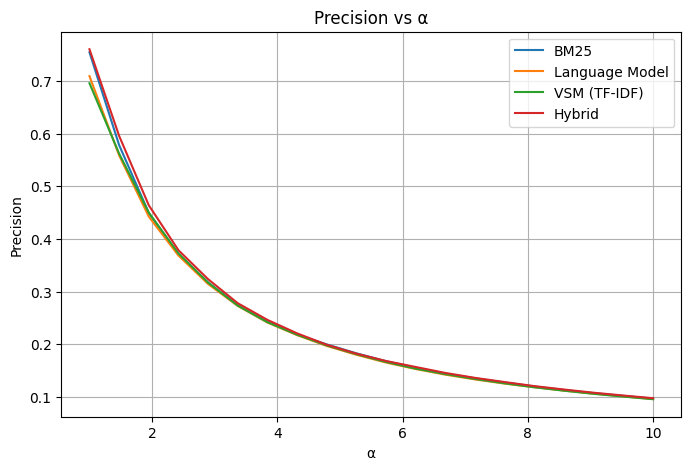

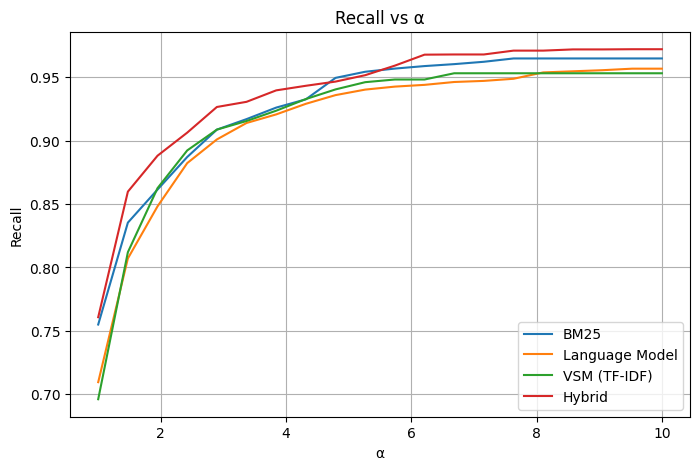

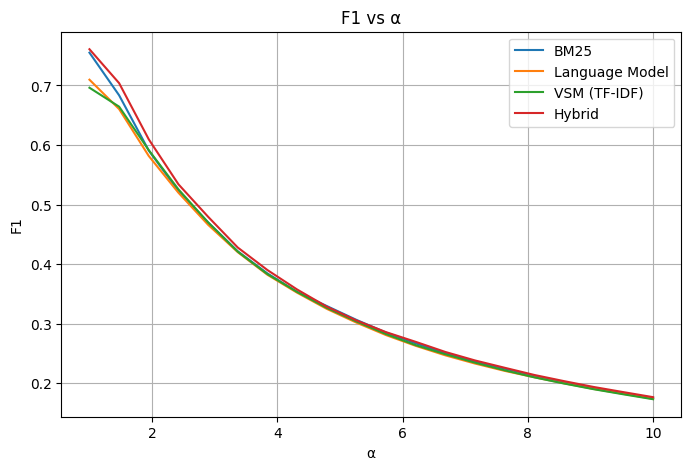

In [25]:
import matplotlib.pyplot as plt

def plot_metric(metric_name, bm25_res, lm_res, vsm_res, hybrid_res, alpha_values):
    plt.figure(figsize=(8,5))
    plt.plot(alpha_values, bm25_res[metric_name], label="BM25")
    plt.plot(alpha_values, lm_res[metric_name], label="Language Model")
    plt.plot(alpha_values, vsm_res[metric_name], label="VSM (TF-IDF)")
    plt.plot(alpha_values, hybrid_res[metric_name], label="Hybrid")
    plt.xlabel("α")
    plt.ylabel(metric_name.capitalize())
    plt.title(f"{metric_name.capitalize()} vs α")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_metric("precision", bm25_res, lm_res, vsm_res, hybrid_res, alpha_values)
plot_metric("recall", bm25_res, lm_res, vsm_res, hybrid_res, alpha_values)
plot_metric("f1", bm25_res, lm_res, vsm_res, hybrid_res, alpha_values)
